In [2]:

!pip -q install yfinance pandas numpy matplotlib plotly


In [3]:

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

print("MarketLens environment is ready!")


MarketLens environment is ready!


In [4]:

ticker = "RELIANCE.NS"

stock = yf.Ticker(ticker)

df = stock.history(
    period="1y",
    interval="1d",
    auto_adjust=True
)

if df.empty:
    raise ValueError("No stock data was returned.")

df = df[["Open", "High", "Low", "Close", "Volume"]].copy()

print("Stock:", ticker)
print("Total trading days:", len(df))

display(df.head())


Stock: RELIANCE.NS
Total trading days: 248


,Open,High,Low,Close,Volume
Date,,,,,
2025-11-20 00:00:00+05:30,1522.958509,1543.762346,1519.673648,1541.970581,18171724
2025-11-21 00:00:00+05:30,1533.907853,1550.630583,1533.011971,1539.482056,9615271
2025-11-24 00:00:00+05:30,1542.866382,1542.866382,1524.750193,1528.831299,18433951
2025-11-25 00:00:00+05:30,1528.831331,1552.422208,1518.080988,1532.613770,15033482
2025-11-26 00:00:00+05:30,1535.201854,1564.366932,1533.410089,1562.674805,14054299


In [5]:

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nLatest closing price:")
print(round(float(df["Close"].iloc[-1]), 2))


Dataset shape: (248, 5)

Missing values:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Latest closing price:
1377.5


In [6]:

# Step 6: Calculate Simple Moving Averages

df["SMA_20"] = df["Close"].rolling(
    window=20,
    min_periods=20
).mean()

df["SMA_50"] = df["Close"].rolling(
    window=50,
    min_periods=50
).mean()

print("SMA calculations completed!")

display(df[["Close", "SMA_20", "SMA_50"]].tail(10))


SMA calculations completed!


,Close,SMA_20,SMA_50
Date,,,
2026-11-06 00:00:00+05:30,1320.000000,1216.140002,1235.590000
2026-11-09 00:00:00+05:30,1324.400024,1223.845001,1236.118000
2026-11-11 00:00:00+05:30,1335.400024,1232.670001,1237.182002
2026-11-12 00:00:00+05:30,1339.699951,1241.320001,1238.236001
2026-11-13 00:00:00+05:30,1339.699951,1249.575000,1239.490000
2026-11-16 00:00:00+05:30,1344.800049,1256.065002,1240.206001
2026-11-17 00:00:00+05:30,1367.000000,1263.855005,1241.284001
2026-11-18 00:00:00+05:30,1363.000000,1271.905005,1242.494001
2026-11-19 00:00:00+05:30,1375.599976,1280.235004,1243.566001


In [7]:

# Step 7: Calculate RSI (14-period, Wilder's method)

def calculate_rsi(close, period=14):
    close = close.astype(float)

    delta = close.diff()

    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)

    avg_gain = pd.Series(np.nan, index=close.index)
    avg_loss = pd.Series(np.nan, index=close.index)

    # Initialize with the first 14 price changes
    avg_gain.iloc[period] = gain.iloc[1:period + 1].mean()
    avg_loss.iloc[period] = loss.iloc[1:period + 1].mean()

    # Wilder's smoothing
    for i in range(period + 1, len(close)):
        avg_gain.iloc[i] = (
            avg_gain.iloc[i - 1] * (period - 1)
            + gain.iloc[i]
        ) / period

        avg_loss.iloc[i] = (
            avg_loss.iloc[i - 1] * (period - 1)
            + loss.iloc[i]
        ) / period

    rs = avg_gain / avg_loss.replace(0, np.nan)
    rsi = 100 - (100 / (1 + rs))

    # Handle periods with zero losses or zero gains
    rsi = rsi.mask((avg_loss == 0) & (avg_gain > 0), 100)
    rsi = rsi.mask((avg_gain == 0) & (avg_loss > 0), 0)
    rsi = rsi.mask((avg_gain == 0) & (avg_loss == 0), 50)

    return rsi


df["RSI_14"] = calculate_rsi(df["Close"])

print("RSI calculation completed!")

display(df[["Close", "SMA_20", "SMA_50", "RSI_14"]].tail(10))


RSI calculation completed!


,Close,SMA_20,SMA_50,RSI_14
Date,,,,
2026-11-06 00:00:00+05:30,1320.000000,1216.140002,1235.590000,68.191595
2026-11-09 00:00:00+05:30,1324.400024,1223.845001,1236.118000,68.776360
2026-11-11 00:00:00+05:30,1335.400024,1232.670001,1237.182002,70.248893
2026-11-12 00:00:00+05:30,1339.699951,1241.320001,1238.236001,70.828055
2026-11-13 00:00:00+05:30,1339.699951,1249.575000,1239.490000,70.828055
2026-11-16 00:00:00+05:30,1344.800049,1256.065002,1240.206001,71.588858
2026-11-17 00:00:00+05:30,1367.000000,1263.855005,1241.284001,74.683872
2026-11-18 00:00:00+05:30,1363.000000,1271.905005,1242.494001,73.137874
2026-11-19 00:00:00+05:30,1375.599976,1280.235004,1243.566001,74.900429


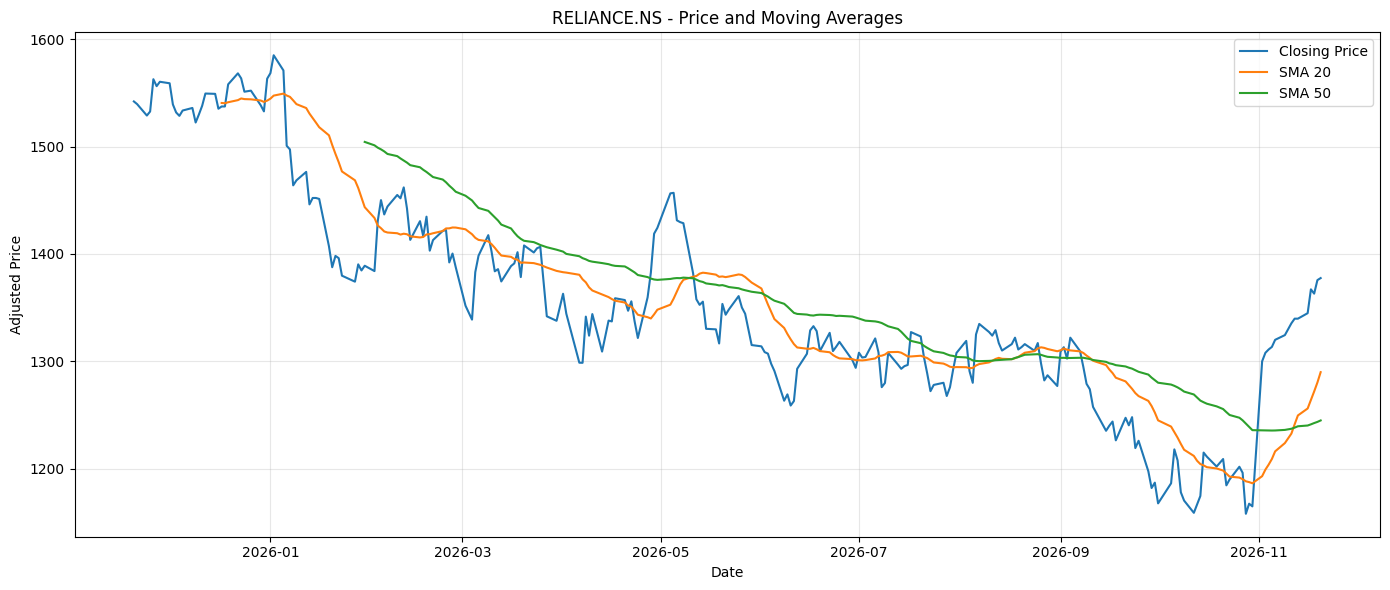

In [8]:

# Step 8: Plot stock price and moving averages

plt.figure(figsize=(14, 6))

plt.plot(
    df.index,
    df["Close"],
    label="Closing Price",
    linewidth=1.5
)

plt.plot(
    df.index,
    df["SMA_20"],
    label="SMA 20",
    linewidth=1.5
)

plt.plot(
    df.index,
    df["SMA_50"],
    label="SMA 50",
    linewidth=1.5
)

plt.title(f"{ticker} - Price and Moving Averages")
plt.xlabel("Date")
plt.ylabel("Adjusted Price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


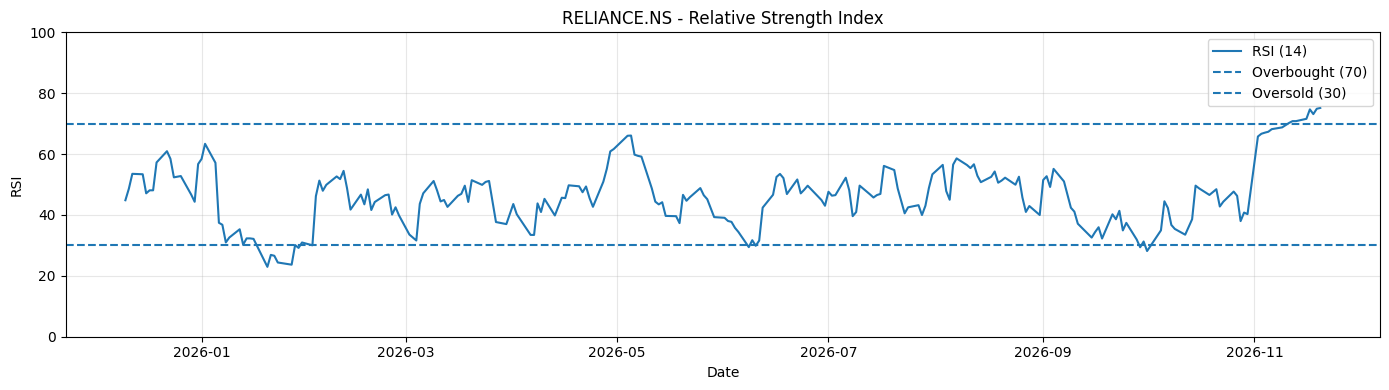

In [9]:

# Step 9: Plot RSI

plt.figure(figsize=(14, 4))

plt.plot(
    df.index,
    df["RSI_14"],
    label="RSI (14)",
    linewidth=1.5
)

plt.axhline(70, linestyle="--", label="Overbought (70)")
plt.axhline(30, linestyle="--", label="Oversold (30)")

plt.ylim(0, 100)
plt.title(f"{ticker} - Relative Strength Index")
plt.xlabel("Date")
plt.ylabel("RSI")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:

# Step 10: Generate a technical analysis summary

latest = df.iloc[-1]

close = float(latest["Close"])
sma20 = float(latest["SMA_20"])
sma50 = float(latest["SMA_50"])
rsi = float(latest["RSI_14"])

print("=" * 45)
print("MARKETLENS - TECHNICAL ANALYSIS REPORT")
print("=" * 45)

print(f"Stock: {ticker}")
print(f"Latest closing price: {close:.2f}")
print(f"SMA 20: {sma20:.2f}")
print(f"SMA 50: {sma50:.2f}")
print(f"RSI 14: {rsi:.2f}")

if close > sma20 and sma20 > sma50:
    trend = "Bullish alignment"
elif close < sma20 and sma20 < sma50:
    trend = "Bearish alignment"
else:
    trend = "Mixed trend"

if rsi > 70:
    momentum = "Overbought zone"
elif rsi < 30:
    momentum = "Oversold zone"
else:
    momentum = "Neutral RSI zone"

print(f"\nTrend: {trend}")
print(f"Momentum: {momentum}")
print("\nNote: Historical indicators are not predictions.")


MARKETLENS - TECHNICAL ANALYSIS REPORT
Stock: RELIANCE.NS
Latest closing price: 1377.50
SMA 20: 1289.89
SMA 50: 1244.93
RSI 14: 75.17

Trend: Bullish alignment
Momentum: Overbought zone

Note: Historical indicators are not predictions.


In [11]:

# Step 11: Export the results

filename = "marketlens_technical_analysis.csv"

df.to_csv(filename)

print(f"Analysis saved successfully: {filename}")


Analysis saved successfully: marketlens_technical_analysis.csv


In [12]:

# Step 12: Interactive Candlestick Chart

import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(go.Candlestick(
    x=df.index,
    open=df["Open"],
    high=df["High"],
    low=df["Low"],
    close=df["Close"],
    name="Candlestick"
))

fig.add_trace(go.Scatter(
    x=df.index,
    y=df["SMA_20"],
    mode="lines",
    name="SMA 20",
    line=dict(color="orange", width=2)
))

fig.add_trace(go.Scatter(
    x=df.index,
    y=df["SMA_50"],
    mode="lines",
    name="SMA 50",
    line=dict(color="blue", width=2)
))

fig.update_layout(
    title=f"MarketLens - {ticker} Technical Analysis",
    xaxis_title="Date",
    yaxis_title="Adjusted Price",
    template="plotly_dark",
    height=650,
    xaxis_rangeslider_visible=False
)

fig.show()


In [13]:

# Step 13: Daily Returns

df["Daily_Return"] = df["Close"].pct_change() * 100

print("Daily returns calculated!")

display(df[["Close", "Daily_Return"]].tail(10))


Daily returns calculated!


,Close,Daily_Return
Date,,
2026-11-06 00:00:00+05:30,1320.000000,0.502511
2026-11-09 00:00:00+05:30,1324.400024,0.333335
2026-11-11 00:00:00+05:30,1335.400024,0.830565
2026-11-12 00:00:00+05:30,1339.699951,0.321995
2026-11-13 00:00:00+05:30,1339.699951,0.000000
2026-11-16 00:00:00+05:30,1344.800049,0.380690
2026-11-17 00:00:00+05:30,1367.000000,1.650799
2026-11-18 00:00:00+05:30,1363.000000,-0.292612
2026-11-19 00:00:00+05:30,1375.599976,0.924430


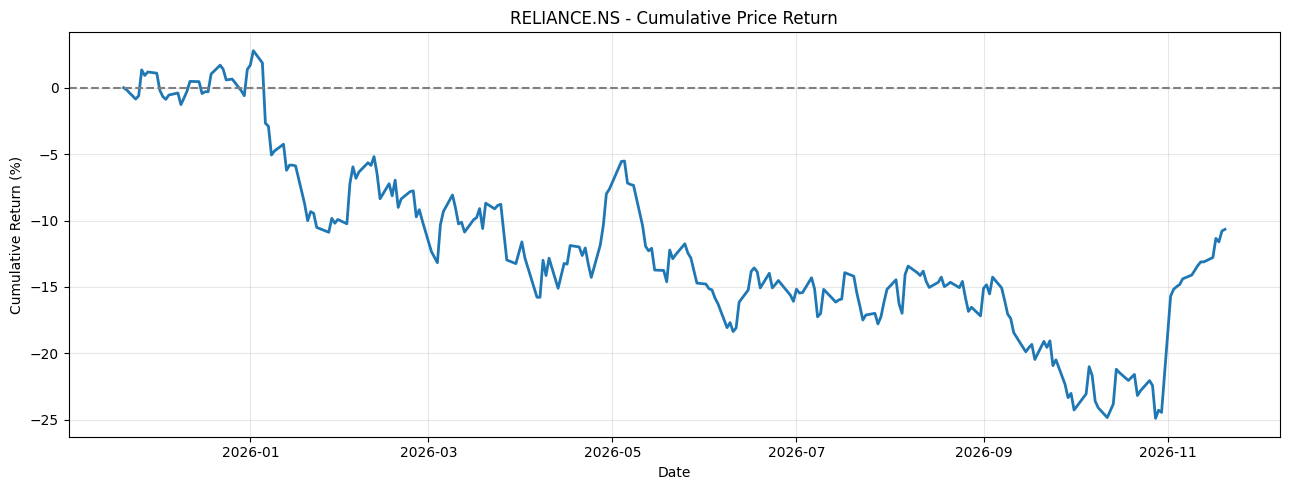

In [14]:

# Step 14: Cumulative Returns

df["Cumulative_Return"] = (
    df["Close"] / df["Close"].iloc[0] - 1
) * 100

plt.figure(figsize=(13, 5))

plt.plot(
    df.index,
    df["Cumulative_Return"],
    linewidth=2
)

plt.axhline(0, linestyle="--", color="gray")

plt.title(f"{ticker} - Cumulative Price Return")
plt.xlabel("Date")
plt.ylabel("Cumulative Return (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [15]:

# Step 15: Annualized Historical Volatility

daily_returns = df["Daily_Return"].dropna() / 100

annual_volatility = (
    daily_returns.std() * np.sqrt(252) * 100
)

print(
    f"Annualized Historical Volatility: "
    f"{annual_volatility:.2f}%"
)


Annualized Historical Volatility: 24.27%


Maximum Drawdown: -26.94%


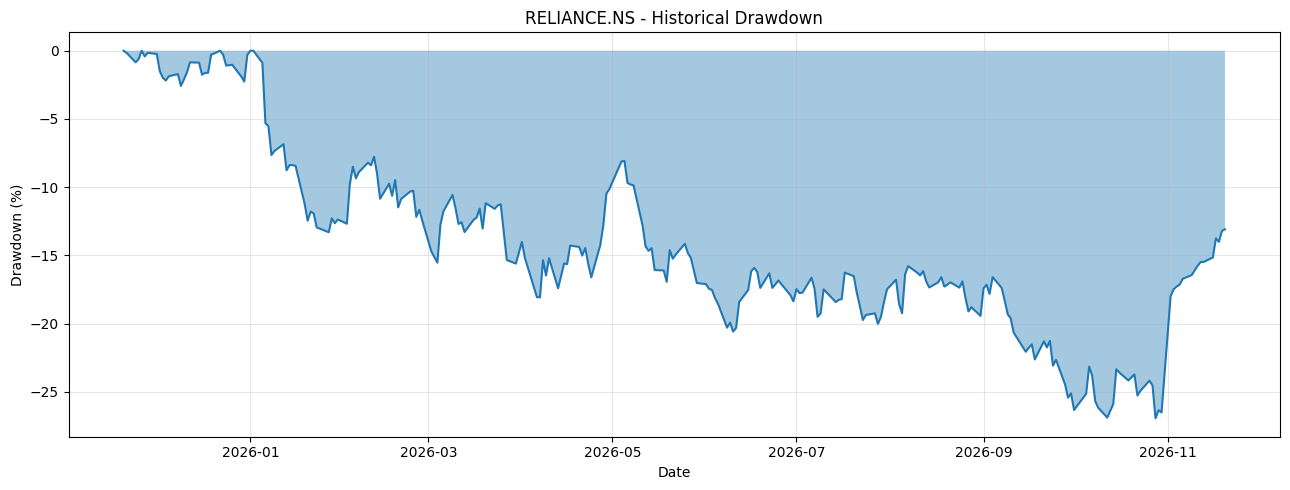

In [16]:

# Step 16: Maximum Drawdown

df["Running_Peak"] = df["Close"].cummax()

df["Drawdown"] = (
    df["Close"] / df["Running_Peak"] - 1
) * 100

max_drawdown = df["Drawdown"].min()

print(f"Maximum Drawdown: {max_drawdown:.2f}%")

plt.figure(figsize=(13, 5))

plt.fill_between(
    df.index,
    df["Drawdown"],
    0,
    alpha=0.4
)

plt.plot(df.index, df["Drawdown"])

plt.title(f"{ticker} - Historical Drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [17]:

# Step 17: MarketLens Risk Analysis Report

latest = df.iloc[-1]

print("=" * 52)
print("MARKETLENS - QUANTITATIVE MARKET ANALYSIS")
print("=" * 52)

print(f"Stock: {ticker}")
print(f"Observations: {len(df)}")
print(f"Latest Closing Price: {latest['Close']:.2f}")
print(f"SMA 20: {latest['SMA_20']:.2f}")
print(f"SMA 50: {latest['SMA_50']:.2f}")
print(f"RSI 14: {latest['RSI_14']:.2f}")

print("-" * 52)

print(
    f"Cumulative Price Return: "
    f"{latest['Cumulative_Return']:.2f}%"
)

print(
    f"Annualized Historical Volatility: "
    f"{annual_volatility:.2f}%"
)

print(f"Maximum Drawdown: {max_drawdown:.2f}%")

print("-" * 52)
print("For educational research, not trading advice.")


MARKETLENS - QUANTITATIVE MARKET ANALYSIS
Stock: RELIANCE.NS
Observations: 248
Latest Closing Price: 1377.50
SMA 20: 1289.89
SMA 50: 1244.93
RSI 14: 75.17
----------------------------------------------------
Cumulative Price Return: -10.67%
Annualized Historical Volatility: 24.27%
Maximum Drawdown: -26.94%
----------------------------------------------------
For educational research, not trading advice.


In [18]:

# Step 18: Export Data and Chart

df.to_csv("marketlens_full_analysis.csv")

fig.write_html("marketlens_candlestick_chart.html")

print("Files generated successfully!")
print("1. marketlens_full_analysis.csv")
print("2. marketlens_candlestick_chart.html")


Files generated successfully!
1. marketlens_full_analysis.csv
2. marketlens_candlestick_chart.html


In [19]:

from google.colab import files

files.download("marketlens_full_analysis.csv")
files.download("marketlens_candlestick_chart.html")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>